# Scrapping data

In [ ]:
!pip install google-play-scraper
from google_play_scraper import reviews, Sort, app as get_app_info
import pandas as pd

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.7 MB/s eta 0:00:00


In [ ]:
print("Kelompok 1 : Analisis Bias pada ulasan aplikasi myTelkomsel")

Kelompok 1 : Analisis Bias pada ulasan aplikasi myTelkomsel


In [ ]:
app_id = "com.telkomsel.telkomselcm"
jumlah_ulasan = 500
tahun = 2026

In [ ]:
info = get_app_info(app_id, lang="id", country="id")
hasil, _ = reviews(
    app_id,
    lang='id',  # Bahasa Indonesia
    country='id',  # Indonesia
    sort=Sort.NEWEST,  # Mengambil ulasan terbaru
    count=jumlah_ulasan,  # Jumlah ulasan yang diambil
)

In [ ]:
df_raw = pd.DataFrame(hasil)[["reviewId", "userName", "content", "score", "at", "reviewCreatedVersion"]]
df_raw.columns = ["id_ulasan", "nama_pengguna", "ulasan", "rating", "tanggal", "versi_aplikasi_ulasan"]
df_raw["tanggal"] = pd.to_datetime(df_raw["tanggal"])

In [ ]:
df = df_raw[df_raw['tanggal'].dt.year == tahun].copy()

In [ ]:
nama_file = f"ulasan_mytelkom_{tahun}.csv"
df.to_csv(nama_file, index=False, encoding='utf-8-sig')

<h2>Tokenize (versi lama, tidak dipakai)</h2>
<p>Versi lama menghapus tanda baca tanpa spasi sehingga kata menempel. Pakai bagian Tokenize di bawah.</p>


In [ ]:
# Versi lama, tidak dipakai. Lihat bagian Tokenize setelah 'Load the sheet'.

In [ ]:
# Versi lama, tidak dipakai. Lihat bagian Tokenize setelah 'Load the sheet'.

In [ ]:
# Versi lama, tidak dipakai. Lihat bagian Tokenize setelah 'Load the sheet'.

# Load the sheet instead of scrapping

In [2]:
import pandas as pd

SHEET_ID = "1JVpzO2-EAivK-HwRGoiLHcOTJWzX94UV1T1y1Xz-7Jg"
GID = "1412720530"
URL_SHEET = f"https://docs.google.com/spreadsheets/d/{SHEET_ID}/export?format=csv&gid={GID}"

df = pd.read_csv(URL_SHEET)
df["ulasan"] = df["ulasan"].fillna("").astype(str)   # avoid errors on empty reviews

# Save under the same name the tokenize cell already reads
df.to_csv("ulasan_mytelkom_2026.csv", index=False, encoding="utf-8-sig")

print(f"Loaded {len(df)} rows")
print(df.columns.tolist())
df.head()

Loaded 500 rows
['id_ulasan', 'nama_pengguna', 'ulasan', 'rating', 'tanggal', 'versi_aplikasi_ulasan', 'Bagus', 'Daniel', 'Liza', 'Cila', 'Missy', 'Summary']


,id_ulasan,nama_pengguna,ulasan,rating,tanggal,versi_aplikasi_ulasan,Bagus,Daniel,Liza,Cila,Missy,Summary
0,c0189ec1-51f2-4d64-a974-a23f6e953702,Rizaldy Rais,jaringan Telkomsel wilayah Agam timur sangat l...,1,2026-09-17 12:47:48,9.3.2000,negative,negative,negative,negative,negative,negative
1,32c878a1-25c9-46c8-a645-a506f422f236,Darwin Ipin,mantap,5,2026-09-17 12:46:36,9.3.2000,positive,positive,positive,positive,positive,positive
2,46728e9d-95a0-42cc-a3d7-79727e140e24,Endang Setiasih,Suka kluar sendiri padahal hp ram 8 aneh nih a...,1,2026-09-17 12:46:30,9.3.2000,negative,negative,negative,negative,negative,negative
3,3a761f28-8040-4395-ba2f-a44f6f8c41b6,Randi Priyanto,maaf ya saya kurangin dulu bintang nya soal ny...,3,2026-09-17 12:46:28,8.6.2002,negative,negative,negative,negative,negative,negative
4,80a08cf2-7248-4efa-9016-95681b423214,eko z,sinyal lemot sering keluar aplikasi sendiri ma...,1,2026-09-17 12:45:37,9.2.2001,negative,negative,negative,negative,negative,negative


# Tokenize

In [3]:
import pandas as pd

# keep_default_na=False supaya ulasan kosong tetap "" (bukan NaN)
df = pd.read_csv("ulasan_mytelkom_2026.csv", keep_default_na=False)
df["ulasan"] = df["ulasan"].astype(str)
df.to_json("ulasan.json", orient="records", lines=True, force_ascii=False)

In [4]:
import json
import re
import nltk
from nltk.tokenize import word_tokenize

INPUT_PATH = "ulasan.json"
OUTPUT_PATH = "ulasan_tokenized_nltk.json"

nltk.download("punkt")
nltk.download("punkt_tab")

ANGKA = {"satu": "1", "dua": "2", "tiga": "3", "empat": "4", "lima": "5"}

def gabung_bintang(teks):
    # "satu bintang", "bintang 1", "1 bintang" -> "bintang_1" (satu token)
    # Harus dilakukan sebelum tokenisasi karena butuh dua kata sekaligus.
    pola_angka = r"(satu|dua|tiga|empat|lima|[1-5])"
    teks = re.sub(rf"\b{pola_angka}\s*bintang\b",
                  lambda m: "bintang_" + ANGKA.get(m.group(1), m.group(1)), teks)
    teks = re.sub(rf"\bbintang\s*{pola_angka}\b",
                  lambda m: "bintang_" + ANGKA.get(m.group(1), m.group(1)), teks)
    return teks

def tokenize(teks):
    teks = str(teks).lower()
    teks = gabung_bintang(teks)
    for tanda in [".", ",", ";", ":", "?", "!"]:
        teks = teks.replace(tanda, " ")  # diganti spasi supaya kata tidak menempel
    return word_tokenize(teks)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [5]:
df = pd.read_json(INPUT_PATH, lines=True)
df["ulasan"] = df["ulasan"].fillna("").astype(str)
df["tokens"] = df["ulasan"].apply(tokenize)
df.to_json(OUTPUT_PATH, orient="records", force_ascii=False, indent=2)
print(f"NLTK tokenize DONE: {OUTPUT_PATH}")

NLTK tokenize DONE: ulasan_tokenized_nltk.json


# Normalization

In [6]:
import json
import re
import pandas as pd

INPUT_PATH_NORM = "ulasan_tokenized_nltk.json"
OUTPUT_PATH_NORM = "ulasan_normalized.json"

In [7]:
URL_KAMUS = "https://raw.githubusercontent.com/nasalsabila/kamus-alay/master/colloquial-indonesian-lexicon.csv"

try:
    df_kamus = pd.read_csv(URL_KAMUS).dropna(subset=["slang", "formal"])
    kamus_slang = dict(zip(
        df_kamus["slang"].astype(str).str.lower().str.strip(),
        df_kamus["formal"].astype(str).str.lower().str.strip()
    ))
    print(f"Kamus alay dimuat: {len(kamus_slang)} entri")
except Exception as e:
    kamus_slang = {}
    print(f"Gagal memuat kamus online ({e}), pakai kamus manual saja")

# Kamus manual (menimpa kamus online), termasuk istilah khas ulasan Telkomsel
kamus_manual = {
    "gk": "tidak", "ga": "tidak", "gak": "tidak", "ngak": "tidak", "nggak": "tidak", "tdk": "tidak",
    "yg": "yang", "udh": "sudah", "udah": "sudah", "sdh": "sudah", "blm": "belum", "belom": "belum",
    "bgt": "banget", "sy": "saya", "aq": "aku", "gw": "saya", "gue": "saya",
    "dgn": "dengan", "dg": "dengan", "utk": "untuk", "tp": "tapi", "krn": "karena", "karna": "karena",
    "trs": "terus", "jd": "jadi", "jg": "juga", "lg": "lagi", "bs": "bisa", "bsa": "bisa", "sm": "sama",
    "knp": "kenapa", "gmn": "bagaimana", "gimana": "bagaimana", "kalo": "kalau", "klo": "kalau",
    "dr": "dari", "org": "orang", "hrs": "harus", "msh": "masih", "aja": "saja", "aj": "saja",
    "pake": "pakai", "pakek": "pakai",
    "apk": "aplikasi", "app": "aplikasi", "apl": "aplikasi", "tsel": "telkomsel",
    "kouta": "kuota", "qouta": "kuota", "signal": "sinyal", "singnal": "sinyal",
    "min": "admin", "mimin": "admin",
    "gpp": "tidak apa apa", "gapapa": "tidak apa apa", "mantul": "mantap betul",
    "makasih": "terima kasih", "mksh": "terima kasih", "trims": "terima kasih", "thx": "terima kasih", "tq": "terima kasih",
    "ok": "oke", "okay": "oke", "bgs": "bagus", "lemot": "lambat", "lelet": "lambat",
    "erorr": "error"
}
#kamus_manual update after review
kamus_manual.update({"pket":"paket","eror":"error","ngetod":"ngentod","taaiiiiiiii":"tahi","pol":"banget","pelitt":"pelit","anjig":"anjing","pukii":"puki","provder":"provider","njingg":"anjing"
,"berberapa":"beberapa","loadingnya":"loading","bitang":"bintang","sangtlah":"sangat","semuaa":"semua","jaringannya":"jaringan","indihomenya":"indihome","ajg":"anjing","relog":"login","sebeluh":"sebelah","kont0l":"kontol","byar":"bayar","fix":"perbaiki","mausuk":"masuk",
"mahalin":"mahal","stbill":"stabil","anying":"anjing","gbsa":"tidak","desedot":"disedot","gblok":"goblok","bug":"masalah","mura":"murah","mkasih":"terima kasih","lag":"lambat","samsek":"sama sekali"})
kamus_normalisasi = {**kamus_slang, **kamus_manual}
print(f"Total kamus normalisasi: {len(kamus_normalisasi)} entri")

Kamus alay dimuat: 4330 entri
Total kamus normalisasi: 4385 entri


In [8]:
# Tambahan kamus manual dan pembangunan ulang kamus_normalisasi
kamus_manual.update({
    "enggak": "tidak", "engga": "tidak", "ngga": "tidak", "nggak": "tidak", "kagak": "tidak", "kaga": "tidak", "engak": "tidak",
    "gajelas": "tidak jelas", "gabisa": "tidak bisa", "gada": "tidak ada", "gaada": "tidak ada", "gamau": "tidak mau", "gapernah": "tidak pernah",
    "mb": "mb", "gb": "gb", # Override "mb" in case it was mapped to "mbak"
    "kelemotan": "lambat", "lemotnya": "lambat", "lemoth": "lambat",
    "kuoto": "kuota", "membatu": "membantu", "memuaskn": "memuaskan", "bsgus": "bagus", "sangst": "sangat",
})
kamus_normalisasi = {**kamus_slang, **kamus_manual}
print(f"Total kamus normalisasi setelah update: {len(kamus_normalisasi)} entri")

# Kamus emoji
kamus_emoji = {
    "👍": " bagus ", "👎": " jelek ", "🥰": " suka ", "😍": " suka ", "❤": " suka ",
    "🙏": " terima kasih ", "😡": " marah ", "🤬": " marah ", "😭": " sedih ",
    "😞": " kecewa ", "🤢": " jijik ",
    "🙄": " kesal ", "😤": " kesal ", "😠": " marah ", "😢": " sedih ", "💩": " jelek ",
    "😊": " senang ", "😁": " senang ", "🔥": " mantap ", "💯": " mantap ",
    # 😂 sengaja tidak dipetakan: di ulasan keluhan sering dipakai untuk sarkasme
}
print(f"Kamus emoji dimuat: {len(kamus_emoji)} entri")

Total kamus normalisasi setelah update: 4397 entri
Kamus emoji dimuat: 20 entri


In [9]:
import unicodedata
import re
import pandas as pd # Ensure pandas is imported if not already
## Udah diubah yak
df_tokenized = pd.read_json(INPUT_PATH_NORM, orient="records")

def normalize_token(tokens):
    normalized_tokens_list = []

    for token in tokens:
        token = unicodedata.normalize("NFKC", token).lower()

        for emoji_char, replacement_word in kamus_emoji.items():
            token = token.replace(emoji_char, replacement_word)

        token = re.sub(r'http\S+|www\S+', '', token)
        token = token.replace('-', ' ')
        token = re.sub(r'[^a-z0-9_\s]', ' ', token)
        token = re.sub(r'\s+', ' ', token).strip()
        token = re.sub(r'([a-z])\1{2,}', r'\1', token)


        sub_tokens = token.split()
        processed_sub_tokens = []

        for sub_token in sub_tokens:
            match_repeated_word = re.match(r'([a-z]{2,})2$', sub_token)

            if match_repeated_word:
                base_word = match_repeated_word.group(1)
                processed_sub_tokens.extend([base_word, base_word])
                continue

            first_normalized = kamus_normalisasi.get(sub_token, sub_token)

            for part in first_normalized.split():
                processed_sub_tokens.append(kamus_normalisasi.get(part, part))

        normalized_tokens_list.extend([t for t in processed_sub_tokens if t])

    return normalized_tokens_list

# Store original tokens in 'tokens_asli'
df_tokenized["tokens_asli"] = df_tokenized["tokens"]
# Apply normalization and store in 'tokens' (replacing the original 'tokens' column)
df_tokenized["tokens"] = df_tokenized["tokens"].apply(normalize_token)

df_tokenized.to_json(OUTPUT_PATH_NORM, orient="records", force_ascii=False, indent=2)
print(f"Normalization DONE: {OUTPUT_PATH_NORM}")

Normalization DONE: ulasan_normalized.json


In [10]:
# Cell Tes fungsi normalize_token
tes = [
    (["pollllllllll"], ["banget"]),                 # huruf berulang dipendekkan, lalu pol -> banget
    (["masuk2"], ["masuk", "masuk"]),               # kata ulang
    (["lelet😂😂😂"], ["lambat"]),                    # 😂 sengaja dibuang
    (["gajelas"], ["tidak", "jelas"]),
    (["👍👍"], ["bagus", "bagus"]),
    (["mb"], ["mb"]),
    (["1000", "100000"], ["1000", "100000"]),        # angka tidak boleh dipendekkan
    (["error", "eror", "erorr"], ["error", "error", "error"]),
    (["bintang_1"], ["bintang_1"]),
]

semua_lulus = True
for masukan, harapan in tes:
    hasil = normalize_token(masukan)
    status = "OK  " if hasil == harapan else "GAGAL"
    semua_lulus &= hasil == harapan
    print(f"{status} {masukan} -> {hasil} (harapan {harapan})")

print("\nTES BERHASIL" if semua_lulus else "\nTES GAGAL")

OK   ['pollllllllll'] -> ['banget'] (harapan ['banget'])
OK   ['masuk2'] -> ['masuk', 'masuk'] (harapan ['masuk', 'masuk'])
OK   ['lelet😂😂😂'] -> ['lambat'] (harapan ['lambat'])
OK   ['gajelas'] -> ['tidak', 'jelas'] (harapan ['tidak', 'jelas'])
OK   ['👍👍'] -> ['bagus', 'bagus'] (harapan ['bagus', 'bagus'])
OK   ['mb'] -> ['mb'] (harapan ['mb'])
OK   ['1000', '100000'] -> ['1000', '100000'] (harapan ['1000', '100000'])
OK   ['error', 'eror', 'erorr'] -> ['error', 'error', 'error'] (harapan ['error', 'error', 'error'])
OK   ['bintang_1'] -> ['bintang_1'] (harapan ['bintang_1'])

TES BERHASIL


# Stopword


In [11]:
!pip install Sastrawi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 8.4 MB/s eta 0:00:00


In [12]:
import json
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

In [13]:
factory = StopWordRemoverFactory()
stopwords_sastrawi = factory.get_stop_words()

In [14]:
# Slang (yg, ga, udah, bgt, dst.) sudah diubah ke bentuk baku saat normalisasi,
# jadi yang dicantumkan di sini hanya kata yang masih muncul setelah normalisasi.
stopwords_sastrawi = set(stopwords_sastrawi)   # ubah ke set dulu
stopwords_sastrawi -= {"tidak", "belum", "bukan", "jangan",
                       "bisa", "tapi", "namun", "tanpa", "tolong",
                       "dapat", "harus", "masih", "hanya", "agak"}

In [15]:
stopwords_sastrawi = set(stopwords_sastrawi)

In [16]:
# Kata negasi dan kata yang membentuk frasa sentimen ("tidak bisa", "masih lambat",
# "bagus tapi mahal") dipertahankan supaya bisa ditangkap bigram di TF-IDF.
stopwords_sastrawi -= {"tidak", "belum", "bukan", "jangan", "tanpa",
                       "bisa", "masih", "tapi", "tetapi", "namun"}

In [17]:
import os
import json
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

INPUT_PATH_LIZA = "ulasan_normalized.json" # Relative path is generally better for Colab files
OUTPUT_PATH_LIZA = "ulasan_filtered.json"

if not os.path.exists(INPUT_PATH_LIZA):
    raise FileNotFoundError(f"Error: File '{INPUT_PATH_LIZA}' not found. Please ensure normalization is done and the file exists.")

with open(INPUT_PATH_LIZA, "r", encoding="utf-8") as f:
    data_ulasan = json.load(f)

for item in data_ulasan:
    if "tokens" in item: # Now 'tokens' holds the normalized tokens as per Masalah 3 fix
        tokens_awal = item["tokens"]
        tokens_bersih = [kata for kata in tokens_awal if kata.lower() not in stopwords_sastrawi]
        item["filtered_tokens"] = tokens_bersih
    # All other keys like 'tokens_asli' are preserved because we modify item directly

with open(OUTPUT_PATH_LIZA, "w", encoding="utf-8") as f:
    json.dump(data_ulasan, f, ensure_ascii=False, indent=2)

print(f"stopword DONE: {OUTPUT_PATH_LIZA}")

stopword DONE: ulasan_filtered.json


In [18]:
# Verifikasi: Cek apakah stopword membaca hasil normalisasi
import json

INPUT_PATH_VERIF_STOPWORD = "ulasan_filtered.json"

if not os.path.exists(INPUT_PATH_VERIF_STOPWORD):
    print(f"File '{INPUT_PATH_VERIF_STOPWORD}' belum ada, tidak bisa verifikasi stopword.")
else:
    with open(INPUT_PATH_VERIF_STOPWORD, "r", encoding="utf-8") as f:
        sample_data = json.load(f)

    if sample_data and "tokens_asli" in sample_data[0] and "filtered_tokens" in sample_data[0]:
        print("OK: stopword membaca hasil normalisasi karena 'tokens_asli' dan 'filtered_tokens' ada.")
        # Optional: Further check if filtered_tokens is indeed a subset of tokens_normalized (which is now just 'tokens' in the normalized JSON)
        # For a full check, we'd need to compare content, but key presence is a good start.
    elif sample_data and "tokens" in sample_data[0] and "filtered_tokens" in sample_data[0]:
         print("OK: stopword membaca file dengan key 'tokens' (hasil normalisasi) dan 'filtered_tokens' ada.")
    else:
        print("SALAH: stopword mungkin membaca file yang belum dinormalisasi atau format tidak sesuai.")

OK: stopword membaca hasil normalisasi karena 'tokens_asli' dan 'filtered_tokens' ada.


# Stemming

In [19]:
!pip install Sastrawi -q

In [20]:
import json
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

In [21]:
factory = StemmerFactory()
stemmer = factory.create_stemmer()

In [22]:
INPUT_PATH = "ulasan_filtered.json"
OUTPUT_PATH = "ulasan_Clean.json"

In [23]:
INPUT_PATH = "ulasan_filtered.json"
with open(INPUT_PATH, "r", encoding="utf-8") as f:
    data = json.load(f)

In [24]:
# coba coba
import os
for f in ["ulasan_mytelkom_2026.csv", "ulasan.json", "ulasan_tokenized_nltk.json",
          "ulasan_normalized.json", "ulasan_filtered.json", "ulasan_Clean.json"]:
    print(("OK      " if os.path.exists(f) else "MISSING ") + f)

OK      ulasan_mytelkom_2026.csv
OK      ulasan.json
OK      ulasan_tokenized_nltk.json
OK      ulasan_normalized.json
OK      ulasan_filtered.json
MISSING ulasan_Clean.json


In [25]:
stem_cache = {}

In [26]:
stem_manual = {
    "berikan": "beri", "kurangin": "kurang", "pengecekan": "cek",
    "sebelumnya": "sebelum", "perusahan": "perusahaan", "perusahaan": "perusahaan",
    "bekasi": "bekasi", "bali": "bali", "maluku": "maluku",
}

def stem_word(word):
    if word in stem_manual: # Check manual stem_manual first
        return stem_manual[word]
    # Sastrawi memecah token seperti 'bintang_1' jadi 'bintang 1' dan angkanya hilang di TF-IDF,
    # jadi token yang mengandung angka atau underscore tidak di-stem
    if "_" in word or any(ch.isdigit() for ch in word):
        return word
    if word not in stem_cache:
        stem_cache[word] = stemmer.stem(word)
    return stem_cache[word]

In [27]:
def get_token_key(item):
    for key in ["filtered_tokens", "tokens_filtered", "tokens"]:
        if key in item:
            return key
    raise KeyError(f"Key token tidak ditemukan: {list(item.keys())}")

In [28]:
if "stem_cache" not in globals():
    stem_cache = {}

cleaned_data = []
for item in data:
    token_key = get_token_key(item)
    # Modified line: filter out empty stemmed tokens
    stemmed = [s for s in (stem_word(t) for t in item[token_key]) if s.strip()]
    cleaned_data.append({
        **{k: v for k, v in item.items() if k != token_key}, # Remove the key that held the tokens for stemming
        "tokens_stemmed": stemmed,
        "ulasan_clean": " ".join(stemmed),
    })

In [29]:
with open(OUTPUT_PATH, "w", encoding="utf-8") as f:
    json.dump(cleaned_data, f, ensure_ascii=False, indent=2)

In [30]:
print(f"Selesai. {len(cleaned_data)} ulasan di-stem. Disimpan di {OUTPUT_PATH}")

Selesai. 500 ulasan di-stem. Disimpan di ulasan_Clean.json


<h1>Vectorization</h1>

In [31]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

# Since OUTPUT_PATH pointed to ulasan_tokenized_nltk.json during save, we can read from cleaned_data in memory
target = pd.DataFrame(cleaned_data)
target["ulasan_clean"] = target["ulasan_clean"].fillna("").astype(str)

# 1. Buang ulasan yang kosong setelah preprocessing (misalnya isinya hanya emoji)
kosong = target["ulasan_clean"].str.strip() == ""
print(f"Ulasan kosong dibuang: {kosong.sum()}")
target = target[~kosong].reset_index(drop=True)

# 2. Petakan label; label yang tidak dikenal/kosong dicek dulu, lalu dibuang
label_map = {"negative": -1, "neutral": 0, "positive": 1}
print(target["Summary"].value_counts(dropna=False))
target["target"] = target["Summary"].astype(str).str.strip().str.lower().map(label_map)
print(f"Baris tanpa label valid dibuang: {target["target"].isna().sum()}")
target = target.dropna(subset=["target"]).reset_index(drop=True)
target["target"] = target["target"].astype(int)
print(f"Jumlah data untuk model: {len(target)}")

Ulasan kosong dibuang: 0
Summary
negative    353
positive     96
neutral      51
Name: count, dtype: int64
Baris tanpa label valid dibuang: 0
Jumlah data untuk model: 500


In [32]:
from sklearn.model_selection import train_test_split

# Split dilakukan SEBELUM TF-IDF supaya bobot IDF tidak "melihat" data test (data leakage).
teks = target["ulasan_clean"]
y = target["target"]

teks_train_full, teks_test, y_train_full, y_test = train_test_split(
    teks, y, test_size=0.2, random_state=42, stratify=y
)
# Validation set terpisah untuk early stopping, supaya test set tidak dipakai memilih model
teks_train, teks_val, y_train, y_val = train_test_split(
    teks_train_full, y_train_full, test_size=0.15, random_state=42, stratify=y_train_full
)
print(f"train: {len(teks_train)} | val: {len(teks_val)} | test: {len(teks_test)}")

train: 340 | val: 60 | test: 100


In [33]:
# TF-IDF di-fit hanya pada data train. Bigram menjaga frasa seperti "tidak bagus".
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
X_train = vectorizer.fit_transform(teks_train).toarray()
X_val = vectorizer.transform(teks_val).toarray()
X_test = vectorizer.transform(teks_test).toarray()

print(X_train.shape, X_val.shape, X_test.shape)
print(vectorizer.get_feature_names_out()[:50])

(340, 729) (60, 729) (100, 729)
['10' '100' '11' '16' '188' '23' '28' '28 hari' '30' '30 hari' '3gb' '4g'
 '5g' '60' 'ada' 'admin' 'aduh' 'agak' 'akal' 'akhir' 'akses' 'aktif'
 'aktif paket' 'aktivitas' 'aku' 'aku beli' 'akun' 'akun sendiri' 'alas'
 'ampun' 'anak' 'aneh' 'anjing' 'anti' 'anti spam' 'apa' 'apa bagaimana'
 'apa coba' 'apa sih' 'apa telkomsel' 'aplikasi' 'aplikasi bayar'
 'aplikasi berat' 'aplikasi bisa' 'aplikasi buat' 'aplikasi buruk'
 'aplikasi error' 'aplikasi kalau' 'aplikasi lambat' 'aplikasi nya']


<h2>Imbalance seen as a problem that need to be faced</h2>

In [34]:
print("Seluruh data:\n", y.value_counts(), "\n")
print("Train:\n", y_train.value_counts())

Seluruh data:
 target
-1    353
 1     96
 0     51
Name: count, dtype: int64 

Train:
 target
-1    240
 1     65
 0     35
Name: count, dtype: int64


In [35]:
# Kesepakatan antar-anotator (Fleiss' kappa) untuk analisis bias pelabelan
from statsmodels.stats.inter_rater import aggregate_raters, fleiss_kappa

# Memakai cleaned_data langsung dari memori karena ulasan_Clean.json tidak tersimpan secara fisik dengan nama tersebut
df_label = pd.DataFrame(cleaned_data)
anotator = [c for c in ["Bagus", "Daniel", "Liza", "Cila", "Missy"] if c in df_label.columns]
lab = df_label[anotator].apply(lambda s: s.astype(str).str.strip().str.lower().map(label_map))
lab = lab.dropna().astype(int)  # hanya ulasan yang dilabeli lengkap oleh semua anotator

if len(anotator) >= 2 and len(lab) > 0:
    tabel, _ = aggregate_raters(lab.values)
    print(f"Fleiss' kappa ({len(anotator)} anotator, {len(lab)} ulasan): {fleiss_kappa(tabel):.4f}")
else:
    print("Kolom anotator tidak ditemukan atau labelnya tidak cocok dengan negative/neutral/positive.")

Fleiss' kappa (5 anotator, 500 ulasan): 0.8751


In [36]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.0 MB/s eta 0:00:00


In [37]:
from catboost import CatBoostClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt
import numpy as np

classes = np.array([-1, 0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class weights:", class_weights)

Class weights: {np.int64(-1): np.float64(0.4722222222222222), np.int64(0): np.float64(3.238095238095238), np.int64(1): np.float64(1.7435897435897436)}


In [38]:
import shutil

# Pakai GPU kalau runtime-nya ada GPU, kalau tidak pakai CPU
TASK_TYPE = "GPU" if shutil.which("nvidia-smi") else "CPU"
print("CatBoost task_type:", TASK_TYPE)

model = CatBoostClassifier(
    loss_function="MultiClass",
    eval_metric="MultiClass",
    iterations=500,
    learning_rate=0.05,
    depth=8,
    class_weights=class_weights,
    random_seed=42,
    verbose=100,
    task_type=TASK_TYPE,
)

model.fit(
    X_train,
    y_train,
    eval_set=(X_val, y_val),   # early stopping memakai validation set, bukan test set
    early_stopping_rounds=50
)

y_pred = model.predict(X_test).ravel()

CatBoost task_type: GPU
0:	learn: 1.0673560	test: 1.0692548	best: 1.0692548 (0)	total: 30.5ms	remaining: 15.2s
100:	learn: 0.3972722	test: 0.5419088	best: 0.5419088 (100)	total: 1.71s	remaining: 6.76s
200:	learn: 0.2883315	test: 0.4894464	best: 0.4894464 (200)	total: 11.9s	remaining: 17.7s
300:	learn: 0.2353736	test: 0.4716069	best: 0.4713996 (299)	total: 21.3s	remaining: 14.1s
400:	learn: 0.2036564	test: 0.4586873	best: 0.4586873 (400)	total: 23.9s	remaining: 5.89s
499:	learn: 0.1800654	test: 0.4478026	best: 0.4475192 (483)	total: 24.7s	remaining: 0us
bestTest = 0.4475192323
bestIteration = 483
Shrink model to first 484 iterations.


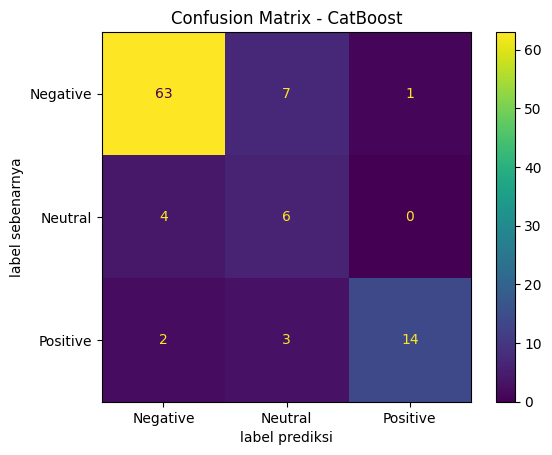

In [39]:
cm = confusion_matrix(y_test, y_pred, labels=[-1, 0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

disp.plot()
plt.title("Confusion Matrix - CatBoost")
plt.xlabel("label prediksi")
plt.ylabel("label sebenarnya")
plt.show()

In [40]:
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression

print(classification_report(y_test, y_pred, labels=[-1, 0, 1],
                            target_names=["Negative", "Neutral", "Positive"], digits=4))
print(f"Macro F1 (test): {f1_score(y_test, y_pred, average='macro'):.4f}")

# Stratified 5-fold CV: test set di atas hanya punya sedikit ulasan Neutral, jadi skornya tidak stabil.
# TF-IDF di-fit ulang di tiap fold. Logistic Regression dipakai sebagai baseline pembanding.
teks_all = target["ulasan_clean"].values
y_all = target["target"].values
best_iter = model.get_best_iteration() + 1
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
skor_cb, skor_lr = [], []

for fold, (idx_tr, idx_te) in enumerate(skf.split(teks_all, y_all), 1):
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
    Xtr = vec.fit_transform(teks_all[idx_tr])
    Xte = vec.transform(teks_all[idx_te])

    w = compute_class_weight("balanced", classes=classes, y=y_all[idx_tr])
    cb = CatBoostClassifier(loss_function="MultiClass", iterations=best_iter, learning_rate=0.05,
                            depth=8, class_weights=dict(zip(classes, w)), random_seed=42,
                            verbose=0, task_type=TASK_TYPE)
    cb.fit(Xtr.toarray(), y_all[idx_tr])
    skor_cb.append(f1_score(y_all[idx_te], cb.predict(Xte.toarray()).ravel(), average="macro"))

    lr = LogisticRegression(max_iter=2000, class_weight="balanced")
    lr.fit(Xtr, y_all[idx_tr])
    skor_lr.append(f1_score(y_all[idx_te], lr.predict(Xte), average="macro"))

print(f"CatBoost  5-fold macro F1: {np.mean(skor_cb):.4f} ± {np.std(skor_cb):.4f}")
print(f"LogReg    5-fold macro F1: {np.mean(skor_lr):.4f} ± {np.std(skor_lr):.4f}")

              precision    recall  f1-score   support

    Negative     0.9130    0.8873    0.9000        71
     Neutral     0.3750    0.6000    0.4615        10
    Positive     0.9333    0.7368    0.8235        19

    accuracy                         0.8300       100
   macro avg     0.7405    0.7414    0.7284       100
weighted avg     0.8631    0.8300    0.8416       100

Macro F1 (test): 0.7284
CatBoost  5-fold macro F1: 0.7512 ± 0.0322
LogReg    5-fold macro F1: 0.7727 ± 0.0498


# Export the result back to the table

In [ ]:
import pandas as pd
import gspread
from google.colab import auth
from google.auth import default

# 1. Log in with your Google account (a popup appears the first time)
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# 2. Prepare the result table
SHEET_ID = "1JVpzO2-EAivK-HwRGoiLHcOTJWzX94UV1T1y1Xz-7Jg"
NAMA_TAB = "hasil_preprocessing"

# Memakai cleaned_data langsung dari memori karena ulasan_Clean.json tidak tersimpan secara fisik dengan nama tersebut
df_clean = pd.DataFrame(cleaned_data)

kolom = ["id_ulasan", "ulasan", "ulasan_clean", "rating",
         "Bagus", "Daniel", "Liza", "Cila", "Missy", "Summary"]
df_clean = df_clean[[k for k in kolom if k in df_clean.columns]]

# Google Sheets rejects NaN, so replace empty values with ""
df_clean = df_clean.astype(object).where(df_clean.notna(), "")
data = [df_clean.columns.tolist()] + df_clean.values.tolist()

# 3. Create the tab, or clear it if it already exists
sh = gc.open_by_key(SHEET_ID)
try:
    ws = sh.worksheet(NAMA_TAB)
    ws.clear()
    ws.resize(rows=len(data), cols=len(data[0]))
except gspread.WorksheetNotFound:
    ws = sh.add_worksheet(title=NAMA_TAB, rows=len(data), cols=len(data[0]))

# 4. Write the data
ws.update(range_name="A1", values=data)

print(f"Done: {len(df_clean)} rows written to tab '{NAMA_TAB}'")
print(f"https://docs.google.com/spreadsheets/d/{SHEET_ID}/edit#gid={ws.id}")